# The Math Behind the Mix
## Building a mini auto-DJ from first principles

**Author:** *Yoana Vladimirova*  
**Course:** Math Concepts for Developers, SoftUni

---

### Abstract
*(Written last: a one-paragraph summary of the problem, methods and main results.)*

## Table of contents
1. Introduction and problem formulation
2. Sound as mathematics
3. Chords, tuning and consonance
4. From audio to pitch: the chromagram
5. Key detection and harmonic distance
6. Tempo detection
7. Evaluation
8. The transition: crossfades and time-stretching
9. Ordering a set: a graph problem
10. Conclusion, limitations and next steps
11. References

## 1. Introduction and problem formulation

A DJ set looks like an artistic act, but underneath it is a chain of mathematical problems. To blend two tracks, we must know their **tempo** and **key**, decide whether they are **compatible**, choose an **order** for the whole set, and **blend** them without an audible jump in rhythm or loudness.

**Research question.** Can each of these steps be solved from first principles, using signal processing, linear algebra, group theory and graph algorithms, and how close do such implementations come to an established library?

Before that, we answer a more basic question that the rest depends on: **why do certain combinations of frequencies (chords) sound consonant, and how does Western music arrive at 12 notes per octave?**

### 1.1 From the real-world problem to a mathematical one

| Real-world question | Mathematical formulation |
|---|---|
| What notes are playing? | Decompose a signal into frequencies (Fourier analysis) |
| Why does a chord sound good? | Ratios between frequencies; sensory dissonance as a function of frequency difference |
| What key is this track in? | Find the key profile with maximum correlation to the pitch-class distribution |
| How fast is it? | Find the dominant period of the onset signal (autocorrelation) |
| Do two tracks fit together? | Distance on a cyclic group of keys, combined with tempo difference |
| What order should they play in? | Shortest Hamiltonian path in a weighted graph |
| How do we blend them? | Gain curves that keep total power constant; time-scale modification |

### 1.2 Scope and assumptions
- Electronic / dance music with a steady tempo; one global tempo and key per track.
- 12-tone equal temperament, A4 ≈ 440 Hz; 24 major/minor keys.
- Tempo in roughly 70–180 BPM; small sets (about 5–15 tracks) for exact ordering.

### 1.3 Existing solutions
Mixed In Key, rekordbox, Serato and Traktor solve these problems commercially; librosa and Essentia are open-source libraries. They are accurate but opaque to the user. This project does not aim to beat them, but to derive, implement and evaluate each method, and to understand where and why it fails.

### 1.4 Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio

import djmath
from djmath.constants import SAMPLE_RATE, A4_FREQUENCY, PITCH_CLASSES

plt.rcParams["figure.figsize"] = (10, 4)
rng = np.random.default_rng(seed=42)  # reproducible experiments

print(f"djmath {djmath.__version__} | sample rate {SAMPLE_RATE} Hz | A4 = {A4_FREQUENCY} Hz")

djmath 0.1.0 | sample rate 22050 Hz | A4 = 440.0 Hz


## 2. Sound as mathematics

Before we can detect keys or tempos, we need a mathematical description of sound and a tool that reveals which frequencies a sound contains. This section builds both: we model sound as a sum of sine waves, and we implement the **discrete Fourier transform (DFT)** to decompose a signal into its frequencies, first directly from its definition and then with the **fast Fourier transform (FFT)**.

### 2.1 Sound as a function of time

Sound is a variation of air pressure over time. The simplest sound, a **pure tone**, is a sine wave:

$$x(t) = A \sin(2\pi f t + \varphi)$$

- $A$ is the **amplitude**, which we perceive as loudness;
- $f$ is the **frequency** in hertz (cycles per second), which we perceive as pitch;
- $\varphi$ is the **phase**, the point in the cycle where the wave starts.

The note A4, the standard tuning reference, is a sine wave with $f = 440$ Hz. Below we plot its first 10 milliseconds, which contain $440 \times 0.01 = 4.4$ cycles.

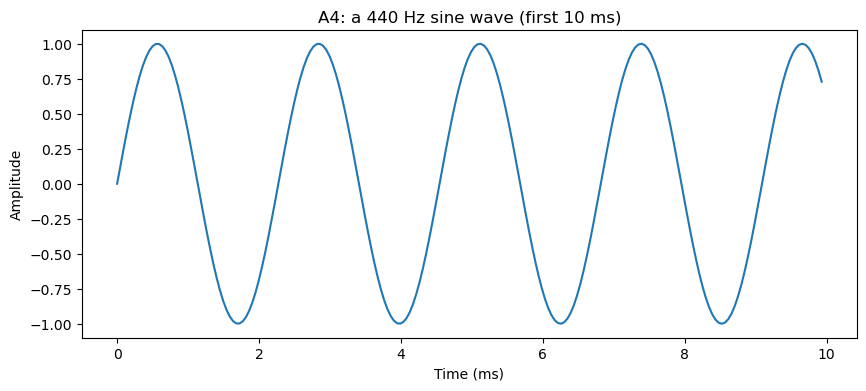

In [2]:
from djmath.signals import sine_wave, time_axis

x = sine_wave(440, duration=1.0)
t = time_axis(1.0)

n_show = int(0.010 * SAMPLE_RATE)   # number of samples in 10 ms
plt.plot(t[:n_show] * 1000, x[:n_show])
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.title("A4: a 440 Hz sine wave (first 10 ms)")
plt.show()

Audio(x, rate=SAMPLE_RATE)

### 2.2 Sampling and aliasing

A computer cannot store a continuous curve, so it measures the signal at regular intervals. With a **sample rate** of $f_s$ samples per second, the $n$-th sample is taken at time $t_n = n / f_s$:

$$x[n] = x\!\left(\frac{n}{f_s}\right), \qquad n = 0, 1, 2, \dots$$

Square brackets denote a discrete signal: a sequence of numbers rather than a function of continuous time. This project uses $f_s = 22\,050$ Hz.

Sampling has a fundamental limit, given by the **Nyquist–Shannon sampling theorem**: a sampled signal can only represent frequencies below the **Nyquist frequency** $f_s / 2$, here $11\,025$ Hz. A higher frequency does not disappear. It becomes indistinguishable from a lower one, an effect called **aliasing**. A tone of frequency $f$ with $f_s/2 < f < f_s$ produces exactly the same samples (up to a sign) as a tone of frequency $f_s - f$.

We test this prediction: a 15 000 Hz tone should look like a $22\,050 - 15\,000 = 7\,050$ Hz tone.

In [3]:
from djmath.signals import magnitude_spectrum

low = sine_wave(7_050, duration=1.0)
high = sine_wave(15_000, duration=1.0)   # above the Nyquist frequency

for name, signal in [("7 050 Hz", low), ("15 000 Hz", high)]:
    freqs, amps = magnitude_spectrum(signal)
    print(f"Generated {name:>9}: strongest frequency found = {freqs[np.argmax(amps)]:.0f} Hz")

print("Samples identical up to sign:", np.allclose(high, -low))

Generated  7 050 Hz: strongest frequency found = 7050 Hz
Generated 15 000 Hz: strongest frequency found = 7050 Hz
Samples identical up to sign: True


Both tones produce a peak at 7 050 Hz, and their samples are identical apart from the sign. After sampling, the information that the original tone was 15 000 Hz is lost for good. This is why audio must be filtered before sampling, and why the sample rate must exceed twice the highest frequency of interest. Our rate comfortably covers the musical range: the highest note of a piano is about 4 186 Hz.

### 2.3 Harmonics and timbre

Real instruments do not produce pure sine waves. A vibrating string playing a note with **fundamental frequency** $f_0$ also vibrates at $2f_0, 3f_0, 4f_0, \dots$ These components are the **harmonics**, and their relative strengths determine the **timbre**: the reason a piano and a violin playing the same note sound different.

Mathematically, any periodic signal with period $1/f_0$ can be written as a sum of harmonics, its **Fourier series**:

$$x(t) = \sum_{k=1}^{\infty} A_k \sin(2\pi k f_0 t + \varphi_k)$$

A classic example is the **sawtooth wave**, whose $k$-th harmonic has amplitude $A_k = 1/k$. Adding more harmonics brings the sum closer to the sawtooth shape:

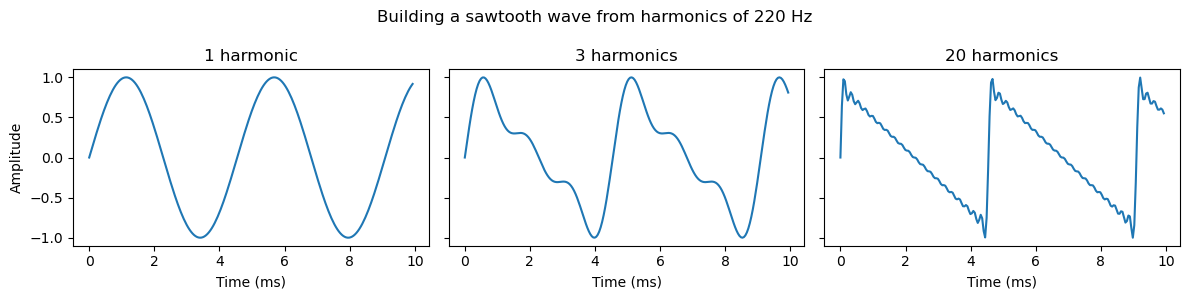

In [4]:
from djmath.signals import harmonic_tone

fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
t_ms = time_axis(0.01) * 1000

for ax, n in zip(axes, [1, 3, 20]):
    ax.plot(t_ms, harmonic_tone(220, duration=0.01, n_harmonics=n))
    ax.set_title(f"{n} harmonic{'s' if n > 1 else ''}")
    ax.set_xlabel("Time (ms)")
axes[0].set_ylabel("Amplitude")
plt.suptitle("Building a sawtooth wave from harmonics of 220 Hz")
plt.tight_layout()
plt.show()

The spectrum of a 220 Hz tone with 10 harmonics should show peaks at multiples of 220 Hz, with heights falling as $1/k$:

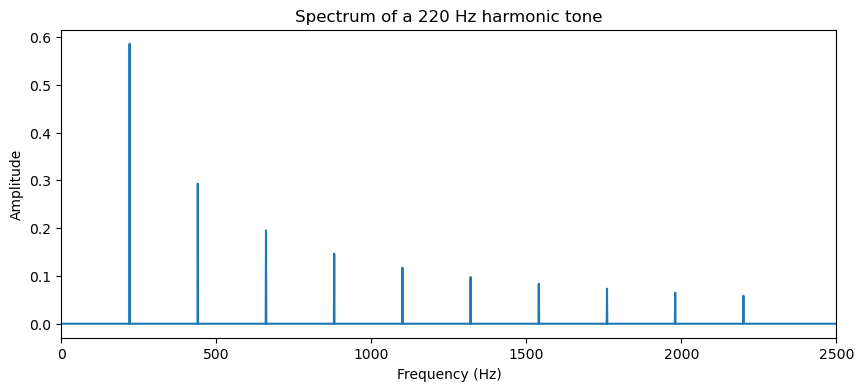

In [5]:
tone = harmonic_tone(220, duration=1.0, n_harmonics=10)
freqs, amps = magnitude_spectrum(tone)

plt.plot(freqs, amps)
plt.xlim(0, 2500)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Spectrum of a 220 Hz harmonic tone")
plt.show()

Audio(tone, rate=SAMPLE_RATE)

For comparison, the pure 220 Hz sine has the same pitch but a much thinner sound, because it contains only the fundamental:

In [6]:
Audio(sine_wave(220, duration=1.0), rate=SAMPLE_RATE)

Harmonics will matter again in Section 3: two notes sound consonant largely because many of their harmonics coincide.

### 2.4 The discrete Fourier transform

The spectra above were computed with the **discrete Fourier transform**. Given $N$ samples $x[0], \dots, x[N-1]$, the DFT produces $N$ complex numbers:

$$X[k] = \sum_{n=0}^{N-1} x[n]\, e^{-2\pi i k n / N}, \qquad k = 0, 1, \dots, N-1$$

**Why complex numbers?** By Euler's formula, $e^{i\theta} = \cos\theta + i\sin\theta$. A single complex exponential holds a cosine and a sine together, and multiplying complex numbers adds their angles, which turns trigonometry into algebra. The **magnitude** $|X[k]|$ tells us how strongly a frequency is present, and the **angle** gives its phase.

**What the sum measures.** The term $e^{-2\pi i k n / N}$ is a complex sinusoid that completes exactly $k$ cycles over the $N$ samples. Multiplying the signal by it and summing is a **dot product**, which measures similarity. If the signal contains that frequency, the products reinforce each other and $|X[k]|$ is large. If not, they cancel out. The DFT therefore asks $N$ questions: *how much of frequency $k$ does the signal contain?*

**From bins to hertz.** Bin $k$ corresponds to the frequency

$$f_k = \frac{k \, f_s}{N},$$

so the **frequency resolution** is $f_s / N$. One second of audio gives $N = f_s$ and bins exactly 1 Hz apart.

**Symmetry.** For a real signal, $X[N-k]$ is the complex conjugate of $X[k]$, so the second half of the spectrum mirrors the first. Only bins $0$ to $N/2$, the frequencies up to Nyquist, carry information.

**Amplitude.** A sine of amplitude $A$ produces peaks of height $A N / 2$. Scaling by $2/N$ recovers $A$.

We check these properties on a small example: a 5 Hz sine sampled at 64 Hz for one second, so $N = 64$.

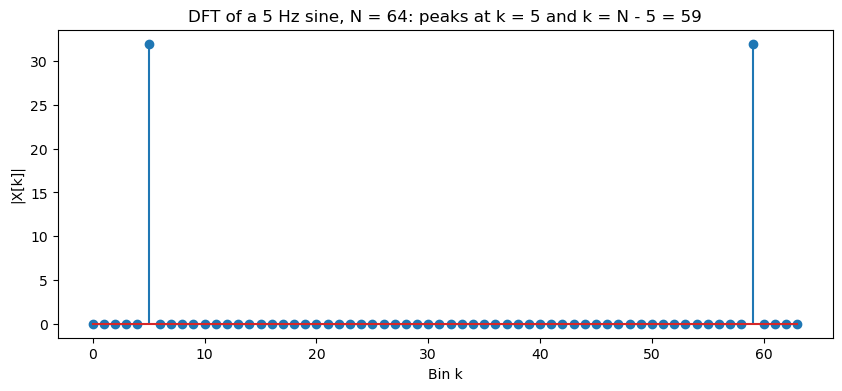

Largest bins: [np.int64(5), np.int64(59)]
Peak height: 32.0 = N/2 = 32


In [7]:
from djmath.signals import dft

small_rate = 64
small = sine_wave(5, duration=1.0, sample_rate=small_rate)   # N = 64 samples
X = dft(small)

plt.stem(np.arange(len(X)), np.abs(X))
plt.xlabel("Bin k")
plt.ylabel("|X[k]|")
plt.title("DFT of a 5 Hz sine, N = 64: peaks at k = 5 and k = N - 5 = 59")
plt.show()

print("Largest bins:", sorted(np.argsort(np.abs(X))[-2:]))
print("Peak height:", round(np.abs(X).max(), 6), "= N/2 =", len(X) // 2)

The peaks sit at $k = 5$ and its mirror $k = 59$, each with height $N/2 = 32$, exactly as predicted.

**Cost.** In matrix form the DFT is $\mathbf{X} = F\mathbf{x}$ with $F_{kn} = e^{-2\pi i k n / N}$: $N$ outputs, each a sum of $N$ terms, so $O(N^2)$ operations. For one second of audio ($N = 22\,050$) that is almost 500 million multiplications, too slow for practical use.

### 2.5 The fast Fourier transform

The **Cooley–Tukey radix-2 FFT** computes exactly the same result in $O(N \log N)$ operations when $N$ is a power of two. It splits the sum into even-indexed and odd-indexed samples. Each half is itself a DFT of length $N/2$; call the results $E[k]$ and $O[k]$. Because $e^{-2\pi i (2m) k / N} = e^{-2\pi i m k / (N/2)}$, the full transform is

$$X[k] = E[k] + w^k O[k], \qquad X[k + N/2] = E[k] - w^k O[k], \qquad w = e^{-2\pi i / N},$$

for $k = 0, \dots, N/2 - 1$. The factors $w^k$ are called **twiddle factors**. Each half is split recursively until the pieces have length 1, where the DFT of a single number is the number itself.

**Complexity.** Combining the two halves costs $O(N)$, so the running time satisfies

$$T(N) = 2\,T(N/2) + O(N).$$

The recursion has $\log_2 N$ levels, each doing $O(N)$ work, so $T(N) = O(N \log N)$. For $N = 2048$ this is roughly $2048 \times 11 \approx 22\,500$ operations instead of about $4.2$ million.

### 2.6 Verification and benchmark

Both implementations live in `djmath/signals.py`. The unit tests in `tests/test_signals.py` confirm that `dft` and `fft` match NumPy's `np.fft.fft` on random signals of several lengths, that a sine of amplitude $A$ produces a single peak of height $A$ at its frequency, and that harmonic amplitudes fall as $1/k$.

To compare speed, we time all three implementations on signals of increasing length. On a **log-log plot**, a running time proportional to $N^p$ appears as a straight line with slope $p$, so we can estimate the exponent from the measurements with a linear fit.

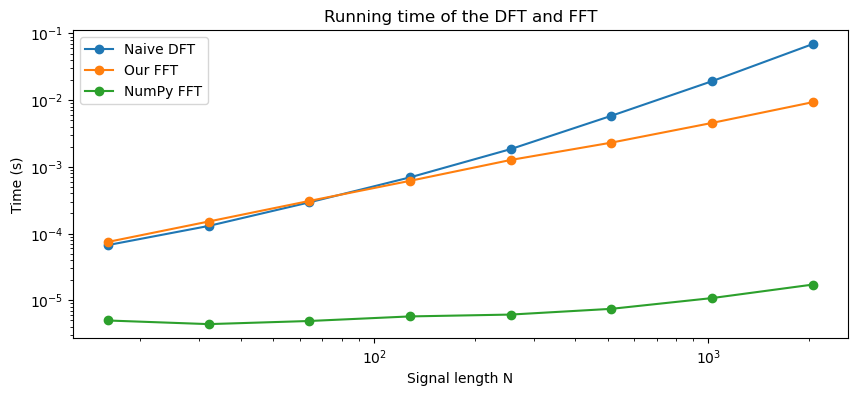

Naive DFT: empirical exponent = 1.67
Our FFT: empirical exponent = 0.97
 Naive DFT:   69.206 ms at N = 2048
   Our FFT:    9.310 ms at N = 2048
 NumPy FFT:    0.017 ms at N = 2048


In [8]:
import timeit
from djmath.signals import fft

sizes = [2**p for p in range(4, 12)]   # 16 to 2048 samples
methods = {"Naive DFT": dft, "Our FFT": fft, "NumPy FFT": np.fft.fft}
timings = {name: [] for name in methods}

for n in sizes:
    x = rng.standard_normal(n)
    for name, func in methods.items():
        best = min(timeit.repeat(lambda: func(x), number=1, repeat=3))
        timings[name].append(best)

for name, times in timings.items():
    plt.loglog(sizes, times, "o-", label=name)
plt.xlabel("Signal length N")
plt.ylabel("Time (s)")
plt.title("Running time of the DFT and FFT")
plt.legend()
plt.show()

# Estimate the exponent p in time ~ N^p from the larger sizes
for name in ["Naive DFT", "Our FFT"]:
    slope, _ = np.polyfit(np.log(sizes[3:]), np.log(timings[name][3:]), deg=1)
    print(f"{name}: empirical exponent = {slope:.2f}")

for name, times in timings.items():
    print(f"{name:>10}: {times[-1] * 1000:8.3f} ms at N = {sizes[-1]}")

**Interpretation.** 

At $N = 2048$, the naive DFT took about 69 ms, our FFT about 9 ms, and NumPy's FFT about 0.02 ms. The gap between the DFT and our FFT grows with $N$, as the complexity analysis predicts.

The fitted exponent for our FFT is close to 1, consistent with $O(N \log N)$: the logarithmic factor grows so slowly that it barely changes the slope. For the naive DFT the fitted exponent (1.65) is below the theoretical 2. Our implementation runs the inner sum with vectorized NumPy operations, so at these sizes a large part of the time is the per-iteration overhead of the Python loop, which grows only linearly. As $N$ increases, the $N^2$ arithmetic dominates and the exponent approaches 2.

NumPy is still hundreds of times faster than our FFT. Both are $O(N \log N)$, but NumPy's FFT is written in compiled C, avoids recursion overhead, and is heavily optimized. Asymptotic complexity describes how running time *scales*, not the constant factor in front of it.

Having validated our implementation against it, we use NumPy's FFT for the rest of the project.

### 2.7 Summary

Sound can be modelled as a function of time, and sampled sound as a sequence of numbers, valid for frequencies below the Nyquist limit. Musical tones are sums of harmonics, and the DFT reveals them by measuring the similarity of a signal with sinusoids of every frequency. The FFT computes the same result in $O(N \log N)$ instead of $O(N^2)$, which makes frequency analysis of real audio practical. The next section uses these tools to explain why some combinations of notes sound consonant.

## 3. Chords, tuning and consonance

Section 2 showed that musical tones are sums of harmonics. This section uses that fact to explain three things a DJ relies on without thinking about them: why notes repeat every octave, why Western music has exactly 12 notes, and why some combinations of notes sound smooth while others sound rough. The answers come from frequency ratios, logarithms, a short number-theory argument and a model of human hearing.

### 3.1 Pitch is logarithmic

Our perception of pitch is logarithmic in frequency: what we hear as equal steps correspond to equal *ratios*. The most important ratio is the **octave**, 2:1. A note and the note with double its frequency sound so similar that they share a name: A3 = 220 Hz, A4 = 440 Hz and A5 = 880 Hz are all called A.

Western music divides the octave into 12 **semitones**. The MIDI standard numbers them, with A4 = 69 and middle C (C4) = 60, and converts between note number $m$ and frequency $f$ with

$$f = 440 \cdot 2^{(m - 69)/12}, \qquad m = 69 + 12 \log_2\!\left(\frac{f}{440}\right).$$

The note name, or **pitch class**, is $m \bmod 12$: the octave is ignored, exactly the folding introduced in Section 1.

In [9]:
from djmath.harmony import midi_to_frequency, frequency_to_midi, note_name

print(f"{'Note':<6}{'MIDI':>5}{'Frequency (Hz)':>16}")
for midi in range(60, 73):                      # one octave, C4 to C5
    name = PITCH_CLASSES[midi % 12] + str(midi // 12 - 1)
    print(f"{name:<6}{midi:>5}{midi_to_frequency(midi):>16.2f}")

print()
for f in [100, 440, 1000]:
    print(f"{f:>5} Hz -> MIDI {frequency_to_midi(f):6.2f} -> nearest note {note_name(f)}")

Note   MIDI  Frequency (Hz)
C4       60          261.63
C#4      61          277.18
D4       62          293.66
D#4      63          311.13
E4       64          329.63
F4       65          349.23
F#4      66          369.99
G4       67          392.00
G#4      68          415.30
A4       69          440.00
A#4      70          466.16
B4       71          493.88
C5       72          523.25

  100 Hz -> MIDI  43.35 -> nearest note G
  440 Hz -> MIDI  69.00 -> nearest note A
 1000 Hz -> MIDI  83.21 -> nearest note B


Each step multiplies the frequency by $2^{1/12} \approx 1.0595$, and after 12 steps C5 has exactly twice the frequency of C4. Frequencies that fall between notes give fractional MIDI numbers: 1000 Hz is about 21 cents above B5. (For simplicity, the project names black keys with sharps only, so E♭ appears as D♯.)

### 3.2 Intervals as frequency ratios

An **interval** is the distance between two notes, and its character depends on the ratio of their frequencies. Since antiquity, the most consonant intervals have been associated with ratios of small whole numbers:

| Interval | Semitones | Ratio |
|---|---|---|
| Octave | 12 | 2:1 |
| Perfect fifth | 7 | 3:2 |
| Perfect fourth | 5 | 4:3 |
| Major third | 4 | 5:4 |
| Minor third | 3 | 6:5 |

Harmonics explain why. A tone at $f_0$ has harmonics $f_0, 2f_0, 3f_0, \dots$. If a second tone is a fifth higher, at $\tfrac{3}{2}f_0$, its harmonics are $\tfrac{3}{2}f_0, 3f_0, \tfrac{9}{2}f_0, 6f_0, \dots$: every second one coincides exactly with every third harmonic of the first tone. The two spectra interlock and few partials end up close together. For a dissonant interval such as the tritone, almost no harmonics coincide, and many fall close to each other.

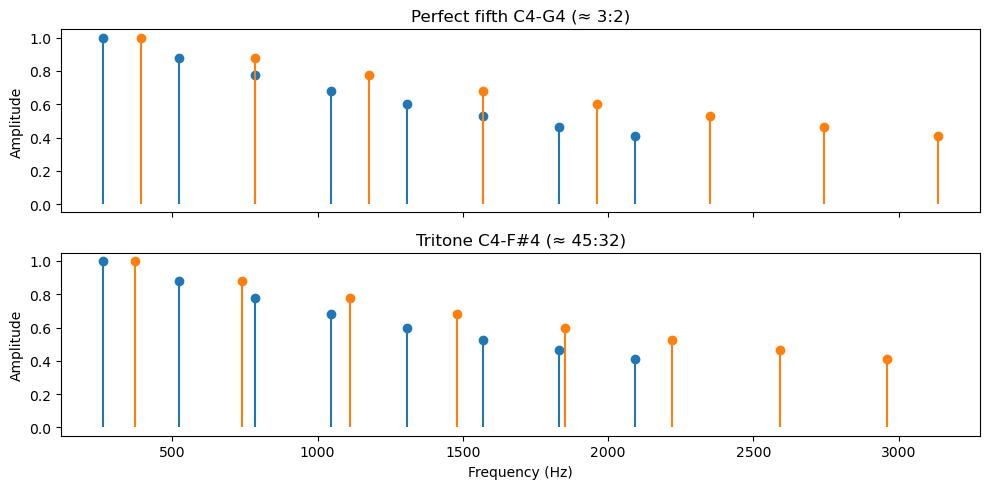

In [10]:
from djmath.harmony import harmonic_spectrum

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
c4 = midi_to_frequency(60)
intervals = [(7, "Perfect fifth C4-G4 (≈ 3:2)"), (6, "Tritone C4-F#4 (≈ 45:32)")]

for ax, (semitones, label) in zip(axes, intervals):
    for f0, color in [(c4, "tab:blue"), (c4 * 2 ** (semitones / 12), "tab:orange")]:
        freqs, amps = harmonic_spectrum(f0, n_harmonics=8)
        ax.stem(freqs, amps, linefmt=color, markerfmt="o", basefmt=" ")
    ax.set_title(label)
    ax.set_ylabel("Amplitude")
axes[1].set_xlabel("Frequency (Hz)")
plt.tight_layout()
plt.show()

In the fifth, blue and orange harmonics regularly land on the same frequency. In the tritone they rarely meet, but often sit uncomfortably close.

### 3.3 Why 12 notes? The Pythagorean comma and equal temperament

If the fifth (3:2) is so consonant, why not build all notes from pure fifths? Stacking fifths from C gives C, G, D, A, E, … and after 12 fifths we arrive back at C, seven octaves higher. Or almost: twelve fifths give the ratio $(3/2)^{12} \approx 129.75$, but seven octaves are $2^7 = 128$.

This is not a rounding problem. A stack of pure fifths can *never* close into octaves exactly: that would require $(3/2)^a = 2^b$ for positive integers $a, b$, i.e. $3^a = 2^{a+b}$. The left side is odd and the right side is even, so by the uniqueness of prime factorisation no such integers exist. The small leftover gap is the **Pythagorean comma**.

Intervals are compared in **cents**, a logarithmic unit in which an octave is 1200 cents:

$$\text{cents}(r) = 1200 \log_2 r.$$

**12-tone equal temperament** solves the problem by giving up exact ratios: every semitone is the same ratio $2^{1/12}$, i.e. exactly 100 cents. All keys become equally usable, which is what lets a DJ move freely between keys, at the cost that every interval except the octave is slightly out of tune compared with its pure ratio.

12 fifths: 129.746, 7 octaves: 128, Pythagorean comma: 23.46 cents

Interval     Just ratio  Just (¢)  Equal (¢)  Error (¢)
Unison                1      0.00          0      +0.00
Minor 2nd         16/15    111.73        100     -11.73
Major 2nd           9/8    203.91        200      -3.91
Minor 3rd           6/5    315.64        300     -15.64
Major 3rd           5/4    386.31        400     +13.69
Perfect 4th         4/3    498.04        500      +1.96
Tritone           45/32    590.22        600      +9.78
Perfect 5th         3/2    701.96        700      -1.96
Minor 6th           8/5    813.69        800     -13.69
Major 6th           5/3    884.36        900     +15.64
Minor 7th           9/5   1017.60       1000     -17.60
Major 7th          15/8   1088.27       1100     +11.73
Octave                2   1200.00       1200      +0.00


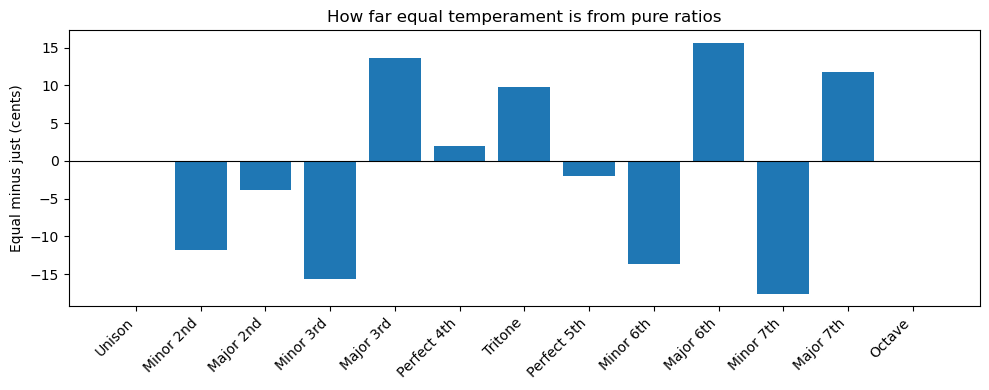

In [11]:
from djmath.harmony import JUST_RATIOS, cents, equal_tempered_ratio

comma = cents((3 / 2) ** 12 / 2**7)
print(f"12 fifths: {(3/2)**12:.3f}, 7 octaves: {2**7}, Pythagorean comma: {comma:.2f} cents\n")

names = ["Unison", "Minor 2nd", "Major 2nd", "Minor 3rd", "Major 3rd", "Perfect 4th",
         "Tritone", "Perfect 5th", "Minor 6th", "Major 6th", "Minor 7th", "Major 7th", "Octave"]
errors = []
print(f"{'Interval':<12}{'Just ratio':>11}{'Just (¢)':>10}{'Equal (¢)':>11}{'Error (¢)':>11}")
for s, name in enumerate(names):
    just = cents(JUST_RATIOS[s])
    equal = 100 * s
    errors.append(equal - just)
    print(f"{name:<12}{str(JUST_RATIOS[s]):>11}{just:>10.2f}{equal:>11.0f}{equal - just:>+11.2f}")

plt.bar(names, errors)
plt.axhline(0, color="black", lw=0.8)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Equal minus just (cents)")
plt.title("How far equal temperament is from pure ratios")
plt.tight_layout()
plt.show()

The fifth and fourth are off by only about 2 cents, too little for most listeners to notice. The thirds and sixths are off by 14 to 16 cents, an audible difference that musicians trained in just intonation can hear. Equal temperament is a compromise that favours the fifth: the interval that, as Section 5 will show, links neighbouring keys on the circle of fifths.

### 3.4 Measuring consonance: sensory dissonance

Ratios tell us *which* intervals are consonant, but not *why* the ear prefers them. In 1965, Plomp and Levelt asked listeners to rate the roughness of two pure sine tones played together. Roughness is zero for identical frequencies, rises quickly to a maximum when the tones are about a quarter of a **critical band** apart (the frequency range over which the inner ear cannot separate two tones), and fades for wider intervals. Sethares fitted their data with the formula

$$d(f_1, f_2) = \min(a_1, a_2)\left(e^{-b_1 s |f_2 - f_1|} - e^{-b_2 s |f_2 - f_1|}\right), \qquad s = \frac{0.24}{0.0207 \min(f_1, f_2) + 18.96},$$

with $b_1 = 3.51$ and $b_2 = 5.75$, where $a_1, a_2$ are the amplitudes. The factor $s$ widens the curve at low frequencies, where the critical band is relatively wider.

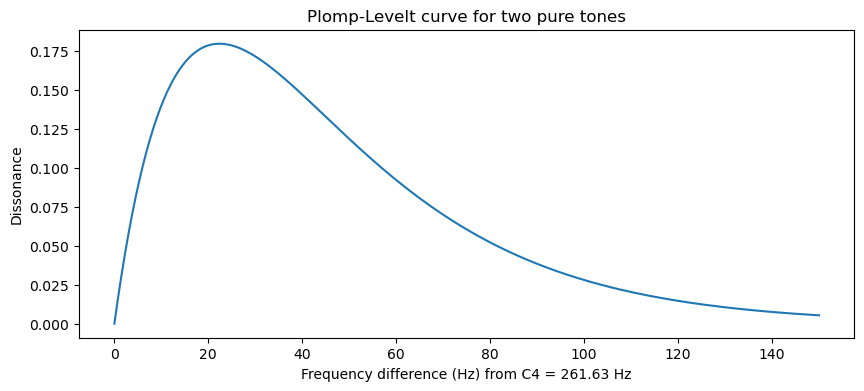

In [12]:
from djmath.harmony import pair_dissonance

f1 = midi_to_frequency(60)
diffs = np.linspace(0, 150, 600)
plt.plot(diffs, [pair_dissonance(f1, f1 + d) for d in diffs])
plt.xlabel("Frequency difference (Hz) from C4 = 261.63 Hz")
plt.ylabel("Dissonance")
plt.title("Plomp-Levelt curve for two pure tones")
plt.show()

Real notes are not pure tones. For two harmonic tones, we add the dissonance of *every pair* of partials. Each tone has 6 harmonics with amplitudes $0.88^{k-1}$. Fixing one note at C4 and sliding the second from the unison up past the octave gives the **dissonance curve**. The gray dotted lines mark the 12 equal-tempered semitones.

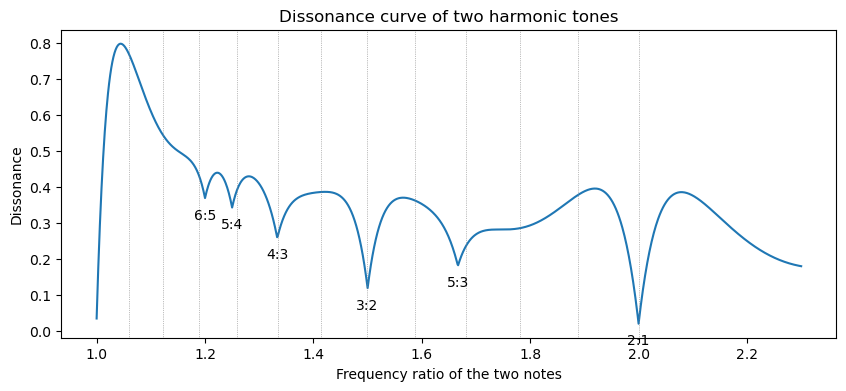

In [13]:
from djmath.harmony import dissonance_curve

ratios = np.linspace(1, 2.3, 1301)
curve = dissonance_curve(f1, ratios)

plt.plot(ratios, curve)
for s in range(1, 13):
    plt.axvline(equal_tempered_ratio(s), color="gray", lw=0.5, ls=":")
for s, label in [(3, "6:5"), (4, "5:4"), (5, "4:3"), (7, "3:2"), (9, "5:3"), (12, "2:1")]:
    r = float(JUST_RATIOS[s])
    plt.annotate(label, (r, curve[np.argmin(np.abs(ratios - r))]),
                 textcoords="offset points", xytext=(0, -15), ha="center")
plt.xlabel("Frequency ratio of the two notes")
plt.ylabel("Dissonance")
plt.title("Dissonance curve of two harmonic tones")
plt.show()

This is the central result of the section. Without any music theory built in, a model of the ear fitted to listening experiments produces **local minima exactly at the classical consonant ratios** 6:5, 5:4, 4:3, 3:2, 5:3 and 2:1. The deepest dips are the octave and the fifth. The unit tests in `tests/test_harmony.py` check these minima automatically.

The equal-tempered semitones land close to most minima: very close for the fourth and fifth, a little off for the thirds and sixths, matching the cent table above. There is also a minimum near 7:4 (≈ 1.75), the "harmonic seventh", which equal temperament does not contain: its minor seventh (1000 cents) lies about 31 cents away.

### 3.5 Chords

A **chord** is three or more notes played together. The basic chords of Western harmony, the **triads**, are built by stacking two thirds on a root note. A major third spans 4 semitones and a minor third 3:

| Triad | Construction | Semitones | Just ratios |
|---|---|---|---|
| Major | major third + minor third | 0, 4, 7 | 4:5:6 |
| Minor | minor third + major third | 0, 3, 7 | 10:12:15 |
| Diminished | minor third + minor third | 0, 3, 6 | |
| Augmented | major third + major third | 0, 4, 8 | |

Because pitch classes are numbers mod 12, the same recipe builds the chord on any root: C major is $\{0, 4, 7\}$ = C, E, G, and D major is $\{2, 6, 9\}$ = D, F♯, A.

In [14]:
from djmath.harmony import CHORD_TYPES, chord_frequencies, chord_dissonance

root = midi_to_frequency(60)
for chord_type in CHORD_TYPES:
    freqs = chord_frequencies(root, chord_type, "equal")
    notes = " ".join(note_name(f) for f in freqs)
    print(f"C {chord_type:<11} {notes:<9} {np.round(freqs, 2)} Hz")

C major       C E G     [261.63 329.63 392.  ] Hz
C minor       C D# G    [261.63 311.13 392.  ] Hz
C diminished  C D# F#   [261.63 311.13 369.99] Hz
C augmented   C E G#    [261.63 329.63 415.3 ] Hz


The dissonance model extends naturally to chords: we combine the harmonics of all three notes and sum over all pairs. As a dissonant reference we add a **cluster** of three adjacent semitones (C, C♯, D). Since every chord has the same number of partials, the totals are directly comparable.

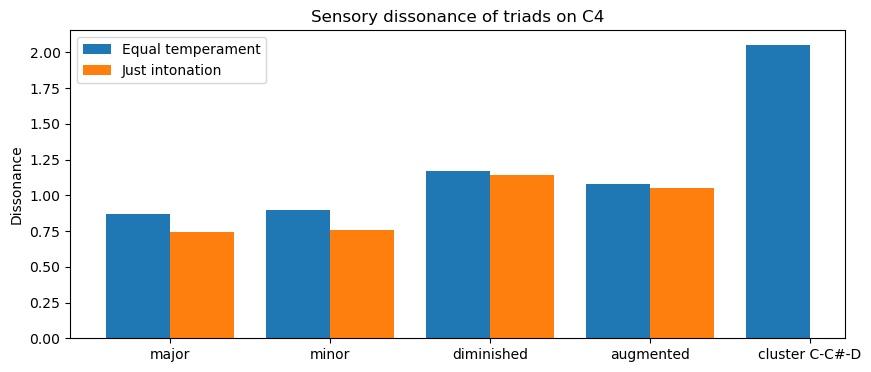

major           0.871
minor           0.900
diminished      1.170
augmented       1.076
cluster C-C#-D  2.051


In [15]:
chords = {name: chord_frequencies(root, name, "equal") for name in CHORD_TYPES}
chords["cluster C-C#-D"] = root * equal_tempered_ratio(np.array([0, 1, 2]))

labels = list(chords)
equal_d = [chord_dissonance(f) for f in chords.values()]
just_d = [chord_dissonance(chord_frequencies(root, name, "just")) for name in CHORD_TYPES]

x = np.arange(len(labels))
plt.bar(x - 0.2, equal_d, width=0.4, label="Equal temperament")
plt.bar(x[:len(just_d)] + 0.2, just_d, width=0.4, label="Just intonation")
plt.xticks(x, labels)
plt.ylabel("Dissonance")
plt.title("Sensory dissonance of triads on C4")
plt.legend()
plt.show()

for label, value in zip(labels, equal_d):
    print(f"{label:<15} {value:.3f}")

The model ranks the chords in the order music theory would: **major < minor < augmented < diminished**, with the cluster far above all of them. Every triad is also slightly smoother in just intonation than in equal temperament, the audible price of the compromise from Section 3.3.

Listen for yourself:

In [16]:
from djmath.signals import harmonic_tone

def play_chord(frequencies, duration=2.0):
    """Synthesize a chord as a sum of harmonic tones and return an audio player."""
    tones = [harmonic_tone(f, duration, n_harmonics=6) for f in frequencies]
    return Audio(np.sum(tones, axis=0) / len(tones), rate=SAMPLE_RATE)

play_chord(chords["major"])

In [17]:
play_chord(chords["minor"])

In [18]:
play_chord(chords["diminished"])

In [19]:
play_chord(chords["cluster C-C#-D"])

### 3.6 Summary

Pitch is logarithmic, so musical intervals are frequency ratios, and the most consonant ones are ratios of small integers, because the harmonics of the two notes coincide. Pure fifths can never close the octave, a consequence of prime factorisation, so modern music uses equal temperament, which divides the octave into 12 equal steps of $2^{1/12}$ at the cost of small tuning errors. A model of sensory roughness fitted to listening experiments reproduces the consonant intervals as minima of the dissonance curve and ranks the triads as music theory does.

For the auto-DJ, the key consequence is that pitch classes form a cycle of 12, and the fifth is the interval that best connects them. Section 4 uses the cycle to measure which pitch classes a track contains; Section 5 uses the fifth to measure which keys mix well together.

## 4. From audio to pitch: the chromagram

To detect chords and keys, we need to know which notes sound at each moment of a track. The Fourier transform of Section 2 analyses a whole signal at once, which mixes everything that happens in a song into one spectrum. This section builds a representation that keeps track of time and keeps only what matters for harmony: the **chromagram**, which shows how strongly each of the 12 pitch classes is present over time.

### 4.1 Cutting the signal into frames: windowing

The idea is to analyse short pieces of the signal, called **frames**, one at a time. But cutting a frame out of a signal creates abrupt edges, and a sine wave whose period does not fit the frame a whole number of times no longer looks like a sine to the DFT. Its energy smears across many frequency bins, an effect called **spectral leakage**.

The remedy is to multiply each frame by a **window** that fades smoothly to zero at both ends. We use the **Hann window**

$$w[n] = \frac{1}{2}\left(1 - \cos\frac{2\pi n}{N}\right), \qquad n = 0, \dots, N-1.$$

Below, a 440.5 Hz sine, deliberately chosen to fall between two bins, is analysed with and without the window. The vertical axis is logarithmic to make the leakage visible. (The windowed spectrum is divided by 0.5, the average value of the window, to keep the peak heights comparable.)

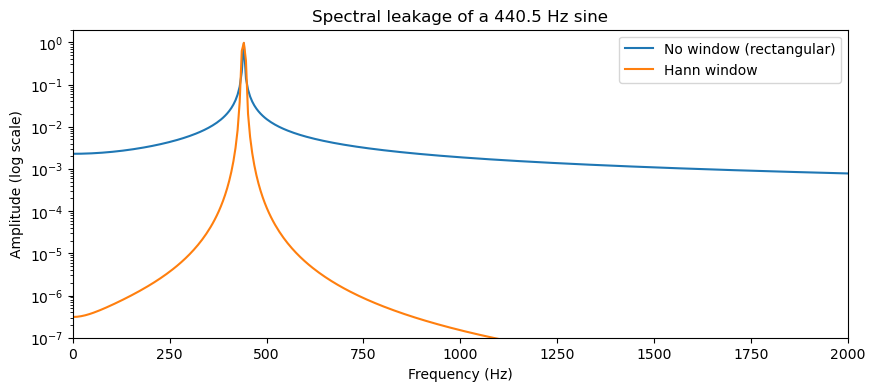

Largest leakage above 600 Hz: no window 5.8e-03, Hann 6.0e-06


In [20]:
from djmath.signals import hann_window

N = 4096
x = sine_wave(440.5, duration=N / SAMPLE_RATE)   # exactly N samples
freqs = np.fft.rfftfreq(N, d=1 / SAMPLE_RATE)
no_window = 2 * np.abs(np.fft.rfft(x)) / N
with_window = 2 * np.abs(np.fft.rfft(x * hann_window(N))) / (N * 0.5)

plt.semilogy(freqs, no_window, label="No window (rectangular)")
plt.semilogy(freqs, with_window, label="Hann window")
plt.xlim(0, 2000)
plt.ylim(1e-7, 2)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude (log scale)")
plt.title("Spectral leakage of a 440.5 Hz sine")
plt.legend()
plt.show()

far = freqs > 600
print(f"Largest leakage above 600 Hz: no window {no_window[far].max():.1e}, "
      f"Hann {with_window[far].max():.1e}")

Without a window, energy leaks across the whole spectrum. With the Hann window, the leakage far from the peak drops by roughly a factor of 1000. The price is a slightly wider main peak, but for identifying notes, a clean background matters more.

### 4.2 The short-time Fourier transform

The **short-time Fourier transform (STFT)** slides a window along the signal and takes the FFT of each frame. With frame length $N$ and **hop length** $H$ (the distance between frame starts), frame $m$ gives

$$X[k, m] = \sum_{n=0}^{N-1} x[n + mH]\, w[n]\, e^{-2\pi i k n / N}.$$

The result is a matrix with frequency bins as rows and frames as columns. Its magnitude, plotted as an image, is the **spectrogram**.

**The time-frequency trade-off.** A frame of $N$ samples has a frequency resolution of $\Delta f = f_s / N$ and lasts $\Delta t = N / f_s$ seconds, so

$$\Delta f \cdot \Delta t = 1.$$

Fine frequency detail requires long frames, which blur changes in time, and vice versa. This is a form of the uncertainty principle. We use $N = 4096$ samples (186 ms, $\Delta f \approx 5.4$ Hz, enough to separate neighbouring low notes) and $H = 1024$ (a new frame every 46 ms, 75 % overlap).

As a test signal, we synthesise the progression **C – Am – F – G**, one of the most common chord sequences in pop music, with each chord lasting 1.5 seconds.

In [21]:
from djmath.harmony import chord_frequencies, midi_to_frequency

progression = [("C", 60, "major"), ("Am", 57, "minor"), ("F", 53, "major"), ("G", 55, "major")]
chord_duration = 1.5

segments = []
for name, root_midi, quality in progression:
    notes = chord_frequencies(midi_to_frequency(root_midi), quality)
    chord = sum(harmonic_tone(f, duration=chord_duration, n_harmonics=6) for f in notes)
    segments.append(chord / len(notes))
song = np.concatenate(segments)

Audio(song, rate=SAMPLE_RATE)

Spectrogram: 2049 frequency bins x 126 frames


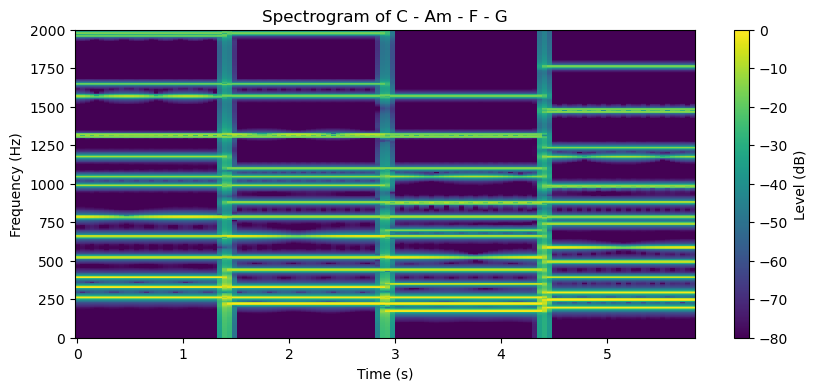

In [22]:
from djmath.signals import stft

frame_length, hop_length = 4096, 1024
freqs, times, mags = stft(song, frame_length=frame_length, hop_length=hop_length)
print(f"Spectrogram: {mags.shape[0]} frequency bins x {mags.shape[1]} frames")

db = 20 * np.log10(mags / mags.max() + 1e-6)   # decibels relative to the loudest bin
plt.pcolormesh(times, freqs, db, shading="auto", vmin=-80, vmax=0)
plt.ylim(0, 2000)
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.title("Spectrogram of C - Am - F - G")
plt.colorbar(label="Level (dB)")
plt.show()

Each chord appears as a stack of horizontal lines, the harmonics of its three notes, and the pattern changes every 1.5 seconds. The colours use **decibels**, $20 \log_{10}$ of the magnitude, a logarithmic scale that, like pitch, matches how we perceive loudness. (The small constant $10^{-6}$ avoids taking the logarithm of zero.)

### 4.3 The chromagram

The spectrogram has over 2000 rows, but for harmony we only need to know which *note names* are present, regardless of octave. Each frequency bin $f$ is assigned to its nearest note and folded into one octave:

$$p(f) = \operatorname{round}\!\left(69 + 12 \log_2 \frac{f}{440}\right) \bmod 12.$$

The **chroma vector** of frame $m$ sums the energy of all bins with the same pitch class:

$$C[p, m] = \sum_{k \,:\, p(f_k) = p} |X[k, m]|^2, \qquad p = 0, \dots, 11.$$

Bins below 55 Hz (A1) and above 5000 Hz are ignored, as they carry little pitch information. Finally, each frame is divided by its largest entry, so the chromagram describes *which* notes are present, independently of how loud the music is.

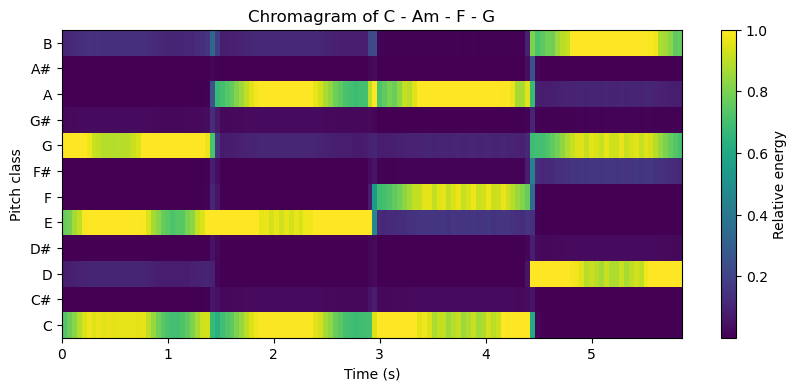

In [23]:
from djmath.harmony import chromagram

chroma = chromagram(freqs, mags)

end_time = times[-1] + hop_length / SAMPLE_RATE
plt.imshow(chroma, aspect="auto", origin="lower", extent=[0, end_time, -0.5, 11.5])
plt.yticks(range(12), PITCH_CLASSES)
plt.xlabel("Time (s)")
plt.ylabel("Pitch class")
plt.title("Chromagram of C - Am - F - G")
plt.colorbar(label="Relative energy")
plt.show()

Over 2000 frequency rows have become 12, and the chords are now readable by eye: C, E, G light up first, then A, C, E, then F, A, C, and finally G, B, D. We can check this numerically by averaging the chroma vectors in the middle of each chord (skipping frames that overlap a chord change):

In [24]:
frame_duration = frame_length / SAMPLE_RATE
for i, (name, _, _) in enumerate(progression):
    start, end = i * chord_duration, (i + 1) * chord_duration
    inside = (times >= start + 0.1) & (times + frame_duration <= end - 0.1)
    mean = chroma[:, inside].mean(axis=1)
    top = [PITCH_CLASSES[pc] for pc in np.argsort(mean)[-3:][::-1]]
    print(f"{name:<3} strongest pitch classes: {', '.join(top)}")

C   strongest pitch classes: G, E, C
Am  strongest pitch classes: E, A, C
F   strongest pitch classes: A, C, F
G   strongest pitch classes: B, D, G


For every chord, the three strongest pitch classes are exactly its three notes. Interestingly, the root is not always the strongest: in C major, G comes first. The reason is the harmonics from Section 3: the third harmonic of C (3 × 261.63 ≈ 785 Hz) is a G, so G receives energy from its own note *and* from the root's harmonics. Real chord recognition must therefore compare the whole chroma pattern with the patterns of known chords, rather than just picking the strongest note. That is the subject of the next part of this section.

### 4.4 Chord recognition by template matching

Instead of picking the strongest notes, we compare the whole chroma vector with an ideal pattern for each chord. A **chord template** is a binary vector with a 1 at each note of the chord: C major, $\{0, 4, 7\}$, has ones at C, E and G. Using the recipes of Section 3.5 on all 12 roots gives 24 templates for the major and minor triads.

We leave out augmented triads, for a mathematical reason: they divide the octave into three equal major thirds, so C augmented $\{0, 4, 8\}$, E augmented $\{4, 8, 0\}$ and G♯ augmented $\{8, 0, 4\}$ contain exactly the same pitch classes. Their templates are identical and no chroma-based method can tell them apart.

To measure how well a chroma vector $\mathbf{c}$ matches a template $\mathbf{t}$, we use the **cosine similarity**

$$\cos\theta = \frac{\mathbf{t} \cdot \mathbf{c}}{\|\mathbf{t}\| \, \|\mathbf{c}\|},$$

the cosine of the angle between the two vectors in 12-dimensional space. It equals 1 when they point in the same direction and does not depend on their lengths, so loudness has no effect. If all templates and all chroma vectors are scaled to unit length, the similarities of every template with every frame are given by a single matrix product:

$$S = T\,\hat{C}, \qquad T \in \mathbb{R}^{24 \times 12}, \quad \hat{C} \in \mathbb{R}^{12 \times M},$$

and each frame is labelled with the chord whose row of $S$ is largest. Frames with no energy are labelled N ("no chord").

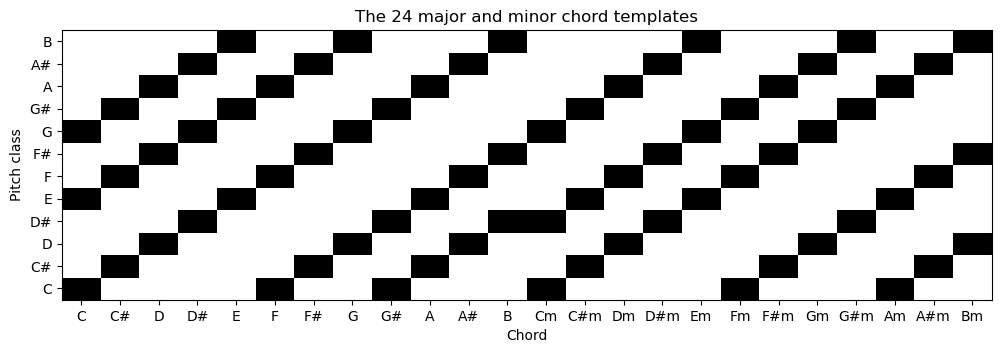

In [25]:
from djmath.harmony import chord_templates

labels, templates = chord_templates()

plt.figure(figsize=(12, 3.5))
plt.imshow(templates.T, aspect="auto", origin="lower", cmap="Greys")
plt.xticks(range(len(labels)), labels)
plt.yticks(range(12), PITCH_CLASSES)
plt.xlabel("Chord")
plt.ylabel("Pitch class")
plt.title("The 24 major and minor chord templates")
plt.show()

Each column is one template. Moving one chord to the right within a group shifts the pattern up by one semitone, a cyclic shift of the vector, which is how all 12 templates of a type are generated from one recipe.

### 4.5 Results on the test progression

We apply the recognizer to the chromagram of C – Am – F – G. Each frame is assigned the true chord playing at its centre, which lets us compute the **frame accuracy**: the fraction of frames labelled correctly.

Frame accuracy on the clean progression: 100.0%


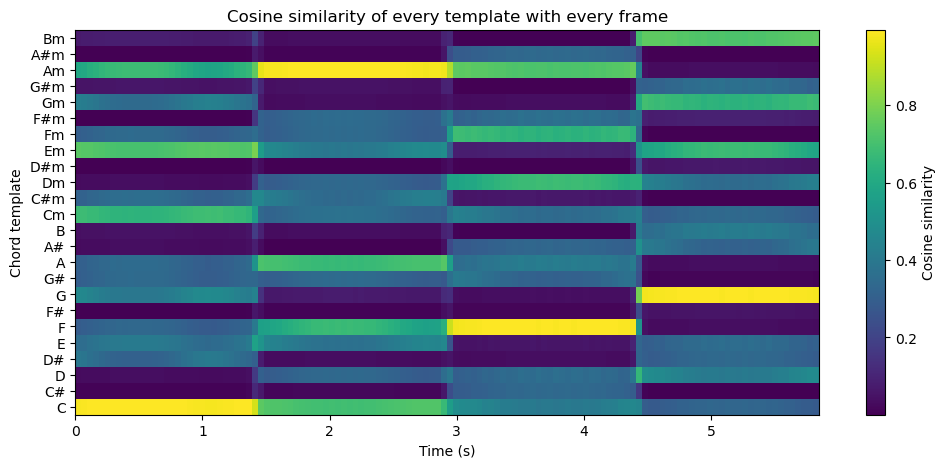

In [26]:
from djmath.harmony import recognize_chords

predicted, similarity = recognize_chords(chroma)

centre = times + frame_length / (2 * SAMPLE_RATE)   # time at the centre of each frame
truth = [progression[min(int(t // chord_duration), len(progression) - 1)][0] for t in centre]

def frame_accuracy(predicted, truth):
    """Fraction of frames whose predicted label equals the true label."""
    return np.mean([p == t for p, t in zip(predicted, truth)])

print(f"Frame accuracy on the clean progression: {frame_accuracy(predicted, truth):.1%}")

plt.figure(figsize=(12, 5))
plt.imshow(similarity, aspect="auto", origin="lower",
           extent=[0, times[-1] + hop_length / SAMPLE_RATE, -0.5, len(labels) - 0.5])
plt.yticks(range(len(labels)), labels)
plt.xlabel("Time (s)")
plt.ylabel("Chord template")
plt.title("Cosine similarity of every template with every frame")
plt.colorbar(label="Cosine similarity")
plt.show()

All frames are recognised correctly. The similarity matrix shows more: besides the winning chord, related chords also score highly. During C major, A minor is a close second, because the two chords share two notes, C and E. This closeness of related chords will matter again in Section 5, where it becomes the basis for measuring which keys mix well.

### 4.6 Robustness to noise

Synthesised chords are an easy case. To test robustness, we add white noise at different **signal-to-noise ratios (SNR)**, measured in decibels:

$$\text{SNR} = 10 \log_{10} \frac{P_\text{signal}}{P_\text{noise}},$$

where $P$ is the average power (mean squared amplitude). At 0 dB the noise is as strong as the music; at −10 dB it is ten times stronger. For each SNR we run 5 trials with different random noise and average the accuracy, with and without smoothing the chromagram by a moving average over 9 frames (about 0.4 s):

$$\tilde{C}[p, m] = \frac{1}{9}\sum_{j=-4}^{4} C[p, m + j].$$

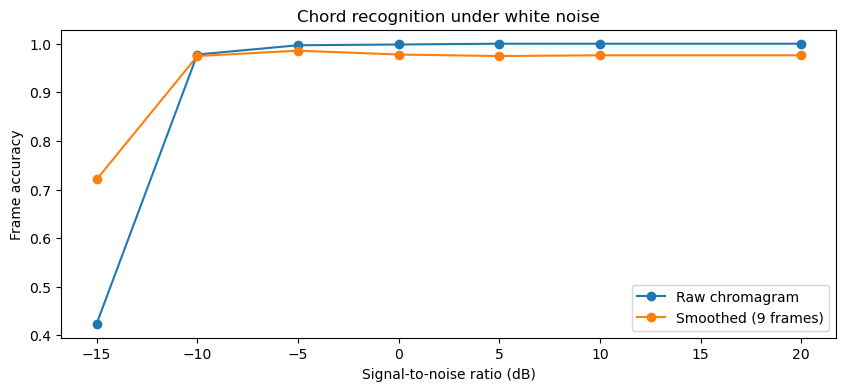

SNR  -15 dB: raw  42.4%   smoothed  72.1%
SNR  -10 dB: raw  97.8%   smoothed  97.5%
SNR   -5 dB: raw  99.7%   smoothed  98.6%
SNR    0 dB: raw  99.8%   smoothed  97.8%
SNR    5 dB: raw 100.0%   smoothed  97.5%
SNR   10 dB: raw 100.0%   smoothed  97.6%
SNR   20 dB: raw 100.0%   smoothed  97.6%


In [27]:
from djmath.harmony import smooth_chroma

def add_noise(signal, snr_db, rng):
    """Add white Gaussian noise at the given signal-to-noise ratio (dB)."""
    signal_power = np.mean(signal**2)
    noise_power = signal_power / 10 ** (snr_db / 10)
    return signal + rng.normal(0, np.sqrt(noise_power), size=signal.shape)

snr_values = [-15, -10, -5, 0, 5, 10, 20]
n_trials = 5
results = {"Raw chromagram": [], "Smoothed (9 frames)": []}

for snr in snr_values:
    raw_scores, smooth_scores = [], []
    for _ in range(n_trials):
        noisy = add_noise(song, snr, rng)
        f, _, m = stft(noisy, frame_length=frame_length, hop_length=hop_length)
        c = chromagram(f, m)
        raw_scores.append(frame_accuracy(recognize_chords(c)[0], truth))
        smooth_scores.append(frame_accuracy(recognize_chords(smooth_chroma(c, width=9))[0], truth))
    results["Raw chromagram"].append(np.mean(raw_scores))
    results["Smoothed (9 frames)"].append(np.mean(smooth_scores))

for name, scores in results.items():
    plt.plot(snr_values, scores, "o-", label=name)
plt.xlabel("Signal-to-noise ratio (dB)")
plt.ylabel("Frame accuracy")
plt.title("Chord recognition under white noise")
plt.legend()
plt.show()

for snr, raw, smooth in zip(snr_values, *results.values()):
    print(f"SNR {snr:>4} dB: raw {raw:6.1%}   smoothed {smooth:6.1%}")

Two results stand out. First, the recogniser is remarkably robust: it stays near 100 % down to −5 dB, where the noise is three times stronger than the music, still reaches about 98 % at −10 dB, and only collapses around −15 dB. White noise spreads its energy over all frequencies, and therefore roughly evenly over all 12 pitch classes. It adds a nearly constant offset to every chroma vector, which shifts all cosine similarities in a similar way and rarely changes which template wins.

Second, smoothing is a **trade-off**. At very low SNR it helps a lot (about 72 % instead of 42 % at −15 dB), because averaging cancels random fluctuations. At higher SNR it costs about 2 percentage points, because averaging across a chord change blurs the boundary, and frames near the change are labelled with the neighbouring chord. This is the time-frequency trade-off of Section 4.2 again, now in time alone: more averaging means more stability but less precision in time. The right amount depends on how noisy the input is and how fast the chords change.

### 4.7 Summary

The STFT turns a signal into a spectrogram, the chromagram folds it into the 12 pitch classes, and cosine similarity with binary templates recognises chords using a single matrix product. On synthesised chords the method is exact and robust to strong noise. Real recordings are harder: drums, vocals and changing timbres add energy that is not evenly spread like white noise. But the chromagram and the idea of comparing pitch-class distributions with ideal patterns carry over directly to key detection in Section 5, where the templates become key profiles.

## 5. Key detection and harmonic distance

Two tracks in compatible keys can be blended smoothly; two tracks in clashing keys produce the sour, dissonant overlap that Section 3 measured. Before we can decide which tracks fit together, we need to know the key of each one.

### 5.1 What is a key?

A **key** is the tonal centre of a piece: a **tonic** note together with a **mode**, major or minor. It determines which 7 of the 12 pitch classes the music mostly uses. C major uses C, D, E, F, G, A, B, the white keys of the piano.

The set of notes alone is not enough to identify a key. A minor uses exactly the same seven notes as C major; such pairs are called **relative keys**. What differs is the *hierarchy* among the notes: in C major, C and G act as points of rest; in A minor, A and E do. A key-finding method must capture how strongly each pitch class is emphasised, not just whether it occurs.

### 5.2 Key profiles

In the 1980s, Krumhansl and Kessler measured this hierarchy experimentally. Listeners heard a passage establishing a key, followed by a single **probe tone**, and rated how well the tone fitted. The average ratings for the 12 pitch classes form a **key profile**:

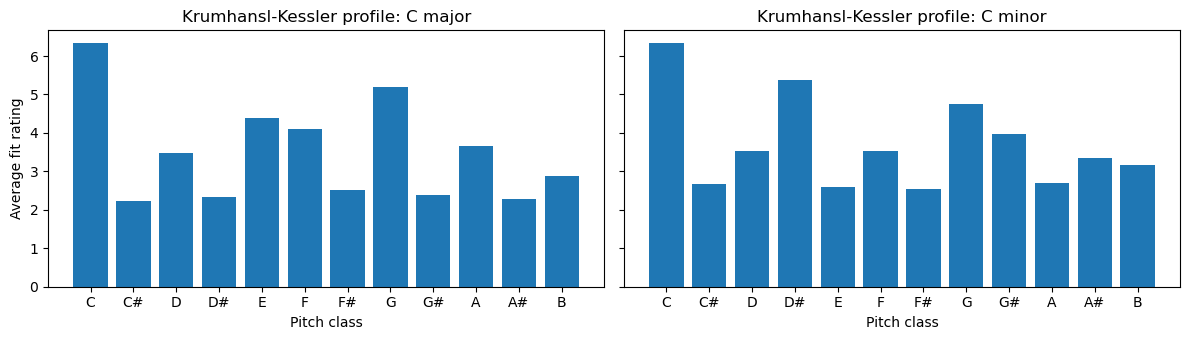

In [28]:
from djmath.key import MAJOR_PROFILE, MINOR_PROFILE

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, profile, title in zip(axes, [MAJOR_PROFILE, MINOR_PROFILE], ["C major", "C minor"]):
    ax.bar(PITCH_CLASSES, profile)
    ax.set_title(f"Krumhansl-Kessler profile: {title}")
    ax.set_xlabel("Pitch class")
axes[0].set_ylabel("Average fit rating")
plt.tight_layout()
plt.show()

The profiles encode music theory, even though they come from listeners rather than rules. In C major, the tonic C is rated highest, followed by G (the fifth) and E (the third), the notes of the tonic triad. Notes of the scale come next, and the five notes outside the scale are rated lowest. In C minor, the minor third E♭ (shown as D♯) takes the place of E.

Since all keys of the same mode share the same hierarchy relative to their tonic, the profile of any key is the C profile **cyclically shifted** by its tonic: shifting the C major profile by 7 positions gives the G major profile. The 12 shifts of the 2 profiles give all 24 keys, the same construction as the chord templates in Section 4.4.

### 5.3 The Krumhansl–Schmuckler algorithm

To estimate the key of a piece, we average its chromagram over time into a single vector $\mathbf{x}$ describing how much each pitch class is used, then compare $\mathbf{x}$ with each key profile $\mathbf{y}$ using the **Pearson correlation**:

$$r(\mathbf{x}, \mathbf{y}) = \frac{\sum_{i}(x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i}(x_i - \bar{x})^2}\sqrt{\sum_{i}(y_i - \bar{y})^2}}.$$

It is the cosine similarity of Section 4.4 applied after subtracting each vector's mean, so it is unaffected by both overall loudness and any constant energy shared by all pitch classes. It ranges from −1 to 1. The key with the highest correlation is the estimate.

We apply it to the progression C – Am – F – G from Section 4:

Estimated key: C major

Five best matches:
  C major    r = 0.913
  A minor    r = 0.824
  E minor    r = 0.683
  G major    r = 0.650
  F major    r = 0.456


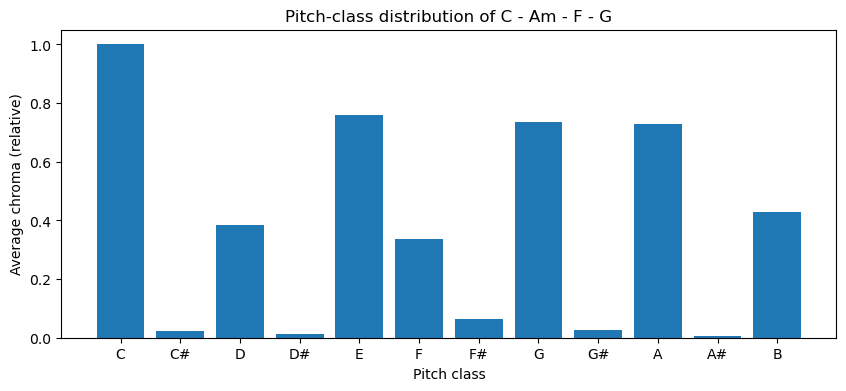

In [29]:
from djmath.key import estimate_key, key_profiles

key, scores = estimate_key(chroma)
labels, _ = key_profiles()

print(f"Estimated key: {key}\n")
print("Five best matches:")
for i in np.argsort(scores)[::-1][:5]:
    print(f"  {labels[i]:<10} r = {scores[i]:.3f}")

mean_chroma = chroma.mean(axis=1)
plt.bar(PITCH_CLASSES, mean_chroma / mean_chroma.max())
plt.xlabel("Pitch class")
plt.ylabel("Average chroma (relative)")
plt.title("Pitch-class distribution of C - Am - F - G")
plt.show()

The progression is correctly identified as **C major**. The runners-up are revealing: A minor (the relative key, same seven notes), then E minor, G major and F major. These are the keys a musician would call *closely related* to C major, and they will be exactly the keys at distance 0 or 1 on the Camelot wheel in Section 5.5. Even when the algorithm is uncertain, its alternatives are musically sensible.

### 5.4 Where key detection fails: low notes

To test the method systematically, we play a **cadence**, the chord sequence that most strongly establishes a key, in all 24 keys: I–IV–V–I in major (for C: C, F, G, C) and i–iv–V–i in minor (for A minor: Am, Dm, E, Am). We repeat the experiment with the tonic in three different octaves.

In [30]:
from djmath.key import key_label

def synthesize_progression(chords, duration=1.0):
    """Concatenate triads given as (root MIDI note, chord type) pairs."""
    segments = []
    for root_midi, chord_type in chords:
        notes = chord_frequencies(midi_to_frequency(root_midi), chord_type)
        segments.append(sum(harmonic_tone(f, duration, n_harmonics=6) for f in notes) / len(notes))
    return np.concatenate(segments)

def cadence(tonic_midi, mode):
    """I-IV-V-I in major, i-iv-V-i in minor, as (root, chord type) pairs."""
    r = tonic_midi
    if mode == "major":
        return [(r, "major"), (r + 5, "major"), (r + 7, "major"), (r, "major")]
    return [(r, "minor"), (r + 5, "minor"), (r + 7, "major"), (r, "minor")]

def evaluate_keys(base_midi, frame_length):
    """Detect the key of a cadence in all 24 keys; return the errors."""
    errors = []
    for mode in ["major", "minor"]:
        for tonic in range(12):
            x = synthesize_progression(cadence(base_midi + tonic, mode))
            f, _, m = stft(x, frame_length=frame_length, hop_length=frame_length // 4)
            detected, _ = estimate_key(chromagram(f, m))
            if detected != key_label(tonic, mode):
                errors.append((key_label(tonic, mode), detected))
    return errors

registers = {"C2 (65 Hz)": 36, "C3 (131 Hz)": 48, "C4 (262 Hz)": 60}
for name, base in registers.items():
    errors = evaluate_keys(base, frame_length=4096)
    print(f"Tonic around {name}: {24 - len(errors)}/24 correct")
    for true, detected in errors:
        print(f"    {true:<9} -> detected {detected}")

Tonic around C2 (65 Hz): 15/24 correct
    D major   -> detected A major
    D# major  -> detected A# major
    A# major  -> detected F major
    C minor   -> detected G major
    D minor   -> detected A major
    D# minor  -> detected A# major
    F minor   -> detected C major
    G minor   -> detected D major
    A# minor  -> detected F major
Tonic around C3 (131 Hz): 24/24 correct
Tonic around C4 (262 Hz): 24/24 correct


In the middle and upper registers all 24 keys are found. In the lowest octave, 9 of 24 fail, and the errors are not random: **every single error is a fifth too high**. D major is mistaken for A major, C minor for G major, and so on.

**Why low notes fail.** The STFT uses frames of 4096 samples, with bins $f_s / N \approx 5.4$ Hz apart. A semitone is a fixed *ratio*, $2^{1/12}$, so its width in hertz shrinks with pitch: around C4 a semitone spans about 15.6 Hz, around C3 about 7.8 Hz, but around C2 only about 3.9 Hz, *less than one bin*. Low fundamentals can no longer be assigned to the right pitch class; their energy smears into neighbouring classes. Meanwhile the higher harmonics, which lie in the well-resolved range, survive. The third harmonic of every note is its fifth (Section 3.2), so the chromagram ends up over-emphasising the fifth above each chord root, pulling the estimate one fifth up.

**Testing the explanation.** If the cause is frequency resolution, longer frames should fix it. We repeat the lowest-octave experiment with longer frames:

In [31]:
for frame_length in [4096, 8192, 16384]:
    errors = evaluate_keys(36, frame_length)
    resolution = SAMPLE_RATE / frame_length
    duration_ms = 1000 * frame_length / SAMPLE_RATE
    print(f"Frame {frame_length:>5} samples (Δf = {resolution:4.2f} Hz, {duration_ms:4.0f} ms): "
          f"{24 - len(errors)}/24 correct")

Frame  4096 samples (Δf = 5.38 Hz,  186 ms): 15/24 correct
Frame  8192 samples (Δf = 2.69 Hz,  372 ms): 23/24 correct
Frame 16384 samples (Δf = 1.35 Hz,  743 ms): 24/24 correct


Doubling the frame length halves the bin spacing, and accuracy climbs from 15 to 23 to all 24 keys, confirming the explanation. The cost is time resolution: a 16384-sample frame lasts almost 0.75 seconds, too long to follow fast chord changes. This is the time-frequency trade-off of Section 4.2 with a concrete consequence. For key detection, which only needs one answer per track, long frames are acceptable; for chord recognition they are not.

All nine errors move the tonic a fifth up, but that does not make them equally harmless, because six of them also change the mode. To judge how serious each error is, we need a precise notion of how far apart two keys are. The next part of this section builds one.

### 5.5 The circle of fifths

Going up a perfect fifth means adding 7 semitones, so in the language of Section 1 it is the map $p \mapsto p + 7 \pmod{12}$. Starting from C and repeating it visits every pitch class exactly once before returning to C after 12 steps. This works because $\gcd(7, 12) = 1$: in the cyclic group $\mathbb{Z}_{12}$, the element 7 is a **generator**. Equivalently, the position of pitch class $p$ on the circle of fifths is

$$\text{pos}(p) = 7p \bmod 12,$$

and this map is a bijection. It is even its own inverse, since $7 \cdot 7 = 49 \equiv 1 \pmod{12}$.

In [32]:
print("Order of the pitch classes on the circle of fifths (7p mod 12):")
order = sorted(range(12), key=lambda p: (7 * p) % 12)
print(" -> ".join(PITCH_CLASSES[p] for p in order) + " -> C")

Order of the pitch classes on the circle of fifths (7p mod 12):
C -> G -> D -> A -> E -> B -> F# -> C# -> G# -> D# -> A# -> F -> C


Neighbours on the circle are keys a fifth apart, and their scales differ in exactly one note: G major is C major with F replaced by F♯. This is why the circle of fifths organises which keys sound close.

### 5.6 The Camelot wheel

DJ software displays the circle of fifths as the **Camelot wheel**. Each major key gets the number of its position (1–12) and the letter B; each minor key gets the number of its relative major and the letter A. By convention C major is 8B, so

$$n = (7t + 7) \bmod 12 + 1,$$

where $t$ is the tonic of the key, or of its relative major for minor keys ($t + 3$).

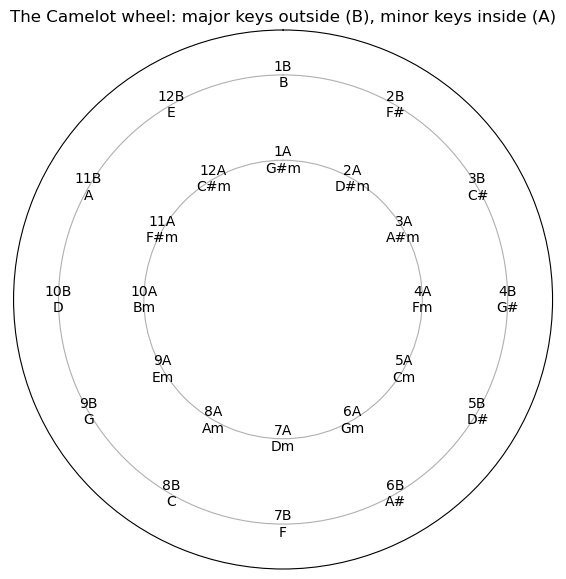

In [33]:
from djmath.key import camelot

fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(projection="polar")
ax.set_theta_zero_location("N")   # 12 o'clock at the top
ax.set_theta_direction(-1)        # numbers increase clockwise

for label in labels:
    number, letter = camelot(label)
    angle = 2 * np.pi * (number - 1) / 12
    radius = 1.0 if letter == "B" else 0.62
    name = label.split()[0] + ("m" if label.endswith("minor") else "")
    ax.text(angle, radius, f"{number}{letter}\n{name}", ha="center", va="center")

ax.set_ylim(0, 1.2)
ax.set_xticks([])
ax.set_yticks([0.62, 1.0])
ax.set_yticklabels([])
ax.set_title("The Camelot wheel: major keys outside (B), minor keys inside (A)")
plt.show()

### 5.7 A distance between keys

The wheel is a graph: its 24 vertices are the keys, and an edge connects two keys if one step turns one into the other. A step either moves the number by ±1 (a fifth up or down, same mode) or switches the letter at the same number (relative major/minor). Algebraically, this is the group $\mathbb{Z}_{12} \times \mathbb{Z}_2$ with those two kinds of step as generators. The **harmonic distance** is the length of the shortest path:

$$d(k_1, k_2) = \min\big(|n_1 - n_2|,\ 12 - |n_1 - n_2|\big) + [\ell_1 \neq \ell_2],$$

where $n_i$ are the numbers, $\ell_i$ the letters, and $[\cdot]$ is 1 if the condition holds and 0 otherwise. The first term is the distance around a cycle of length 12; the second adds one step for changing mode. As a shortest-path distance, $d$ is a **metric**: $d(a, b) = 0$ only if $a = b$, $d(a, b) = d(b, a)$, and $d(a, c) \le d(a, b) + d(b, c)$. The unit tests verify all three properties for every pair and every triple of keys. The largest possible distance is $6 + 1 = 7$.

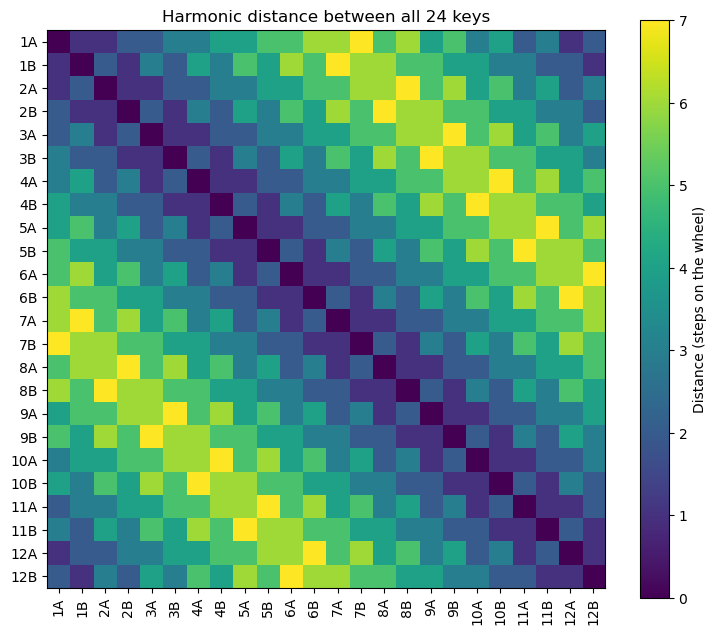

In [34]:
from djmath.key import camelot_code, harmonic_distance

wheel_order = sorted(labels, key=camelot)   # 1A, 1B, 2A, 2B, ...
D = np.array([[harmonic_distance(a, b) for b in wheel_order] for a in wheel_order])
codes = [camelot_code(k) for k in wheel_order]

plt.figure(figsize=(9, 7.5))
plt.imshow(D, cmap="viridis")
plt.xticks(range(24), codes, rotation=90)
plt.yticks(range(24), codes)
plt.title("Harmonic distance between all 24 keys")
plt.colorbar(label="Distance (steps on the wheel)")
plt.show()

The matrix is symmetric with zeros on the diagonal. The dark bands near the diagonal are the safe mixes: the keys within one step.

**Does the distance mean anything musically?** We check it against two independent measures. First, the number of notes two scales share:

In [35]:
from djmath.key import camelot_code, scale_pitch_classes

c_major_notes = scale_pitch_classes("C major")
by_distance = {}
for other in labels:
    d = harmonic_distance("C major", other)
    shared = len(c_major_notes & scale_pitch_classes(other))
    by_distance.setdefault(d, []).append(f"{other} ({shared})")

print("Keys at each distance from C major (number of shared notes):")
for d in sorted(by_distance):
    print(f"  {d}: {', '.join(by_distance[d])}")

Keys at each distance from C major (number of shared notes):
  0: C major (7)
  1: F major (6), G major (6), A minor (7)
  2: D major (5), A# major (5), D minor (6), E minor (6)
  3: D# major (4), A major (4), G minor (5), B minor (5)
  4: E major (3), G# major (3), C minor (4), F# minor (4)
  5: C# major (2), B major (2), C# minor (3), F minor (3)
  6: F# major (2), G# minor (2), A# minor (2)
  7: D# minor (2)


The number of shared notes falls steadily with distance: 7 for C major itself and A minor, 6 for its neighbours, down to 2 for the keys on the opposite side of the wheel.

Second, the similarity of the Krumhansl–Kessler profiles, which come from listening experiments and know nothing about the wheel. For every pair of different keys, we compare their profile correlation with their distance:

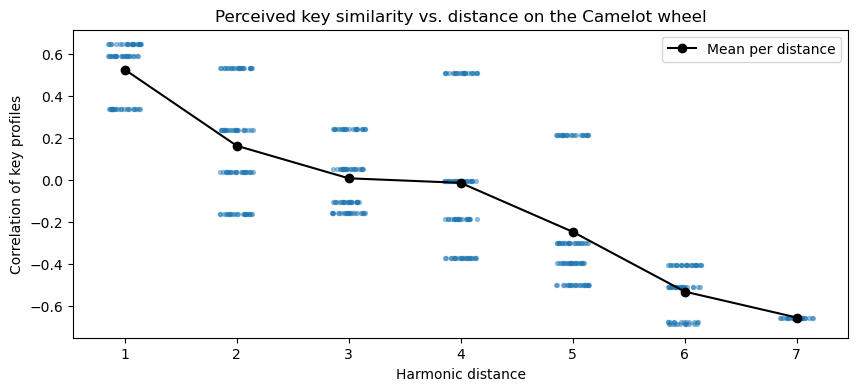

Correlation between distance and profile similarity: -0.80


In [36]:
from djmath.key import correlations

_, profiles = key_profiles()
distances, similarities = [], []
for i, a in enumerate(labels):
    r = correlations(profiles[i], profiles)
    for j, b in enumerate(labels):
        if i != j:
            distances.append(harmonic_distance(a, b))
            similarities.append(r[j])
distances, similarities = np.array(distances), np.array(similarities)

means = [similarities[distances == d].mean() for d in range(1, 8)]
plt.scatter(distances + rng.uniform(-0.15, 0.15, len(distances)), similarities, s=8, alpha=0.4)
plt.plot(range(1, 8), means, "o-", color="black", label="Mean per distance")
plt.xlabel("Harmonic distance")
plt.ylabel("Correlation of key profiles")
plt.title("Perceived key similarity vs. distance on the Camelot wheel")
plt.legend()
plt.show()

print(f"Correlation between distance and profile similarity: {np.corrcoef(distances, similarities)[0, 1]:.2f}")

Profile similarity falls with distance, from about 0.53 for neighbouring keys to about −0.65 for the most distant ones, and the overall correlation is about −0.80. Two independent sources, the arithmetic of the circle of fifths and human listeners' judgements, agree on which keys are close. The small random horizontal shifts in the scatter plot only spread overlapping points so they are visible.

### 5.8 Re-examining the errors

With a distance between keys, we can grade the low-register errors of Section 5.4 instead of just counting them. Besides the distance, we use the standard **MIREX weighted score** from music information retrieval research: 1.0 for the correct key, 0.5 for a perfect fifth above (same mode), 0.3 for the relative key, 0.2 for the parallel key (same tonic, other mode), and 0 otherwise.

In [37]:
from djmath.key import key_score

low_register_errors = evaluate_keys(36, frame_length=4096)

print(f"{'True key':<10}{'Detected':<10}{'Camelot':>12}{'Distance':>10}{'MIREX':>7}{'Shared':>8}")
for true, detected in low_register_errors:
    move = f"{camelot_code(true)} -> {camelot_code(detected)}"
    shared = len(scale_pitch_classes(true) & scale_pitch_classes(detected))
    print(f"{true:<10}{detected:<10}{move:>12}{harmonic_distance(true, detected):>10}"
          f"{key_score(true, detected):>7.1f}{shared:>8}")

n_correct = 24 - len(low_register_errors)
weighted = (n_correct + sum(key_score(t, d) for t, d in low_register_errors)) / 24
print(f"\nPlain accuracy: {n_correct / 24:.1%}   MIREX weighted score: {weighted:.1%}")

True key  Detected       Camelot  Distance  MIREX  Shared
D major   A major     10B -> 11B         1    0.5       6
D# major  A# major      5B -> 6B         1    0.5       6
A# major  F major       6B -> 7B         1    0.5       6
C minor   G major       5A -> 9B         5    0.0       3
D minor   A major      7A -> 11B         5    0.0       3
D# minor  A# major      2A -> 6B         5    0.0       3
F minor   C major       4A -> 8B         5    0.0       3
G minor   D major      6A -> 10B         5    0.0       3
A# minor  F major       3A -> 7B         5    0.0       3

Plain accuracy: 62.5%   MIREX weighted score: 68.8%


The table splits the errors into two very different groups.

The three **major-key errors** (for example D major → A major) are one step clockwise on the wheel, share six notes with the true key, and receive half credit. A DJ mixing on these estimates would still produce a harmonious transition.

The six **minor-key errors** are serious. The tonic moves a fifth up, but the mode also flips to major: C minor becomes G major, five steps away on the wheel, with only three notes in common. A plausible explanation combines two effects. The low-register blur over-emphasises the fifth above every chord root (Section 5.4), and the cadence's V chord is major, adding the raised seventh degree (B in C minor). Together they make the pitch-class distribution resemble the major key on the dominant. The MIREX score gives these errors no credit, and neither should we.

Counting errors alone (62.5 % correct) hides this structure, and the weighted score (68.8 %) only partly reveals it. The harmonic distance shows *how wrong* each estimate is, which is what matters when the estimate decides which tracks are mixed together. Part 3 applies the same evaluation to real recordings.

### 5.9 Key detection on real recordings

Synthetic chords are the ideal case: clean harmonics, no drums, no vocals, no effects. The real test is music. We use the **GiantSteps Key** dataset (Knees et al., 2015), a standard benchmark in music information retrieval research: 604 two-minute previews of electronic dance music from Beatport, with keys annotated by users who corrected the store's automatic key labels. We evaluate on a reproducible random sample of 100 tracks, downloaded with `scripts/download_data.py`. The audio is used locally for research only and is not part of this repository.

Real recordings come as stereo MP3 files at 44 100 Hz. `load_audio` averages the channels and **resamples** to our rate of 22 050 Hz. Simply dropping every second sample would make frequencies above the new Nyquist limit of 11 025 Hz alias into lower ones (Section 2.2), so the resampler first applies a low-pass filter. A unit test confirms that a 15 kHz tone is removed rather than turned into 7 050 Hz.

100 tracks: 88 minor (88%), 12 major


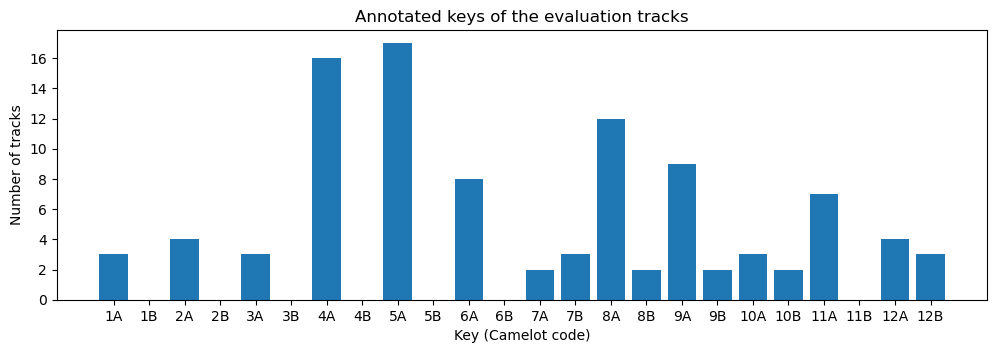

In [38]:
from collections import Counter
from djmath.datasets import load_giantsteps_key

tracks = load_giantsteps_key()
counts = Counter(key for _, key in tracks)
n_minor = sum(n for key, n in counts.items() if key.endswith("minor"))
print(f"{len(tracks)} tracks: {n_minor} minor ({n_minor / len(tracks):.0%}), "
      f"{len(tracks) - n_minor} major")

plt.figure(figsize=(12, 3.5))
plt.bar([camelot_code(k) for k in wheel_order], [counts.get(k, 0) for k in wheel_order])
plt.xlabel("Key (Camelot code)")
plt.ylabel("Number of tracks")
plt.title("Annotated keys of the evaluation tracks")
plt.show()

The sample contains 88 minor and 12 major tracks.

The sample contains [X] minor and [Y] major tracks. Electronic dance music is dominated by minor keys, and the distribution over the wheel is uneven, which matters for interpreting the results: a method that always guessed minor would already be right about the mode most of the time.

We run the same pipeline as in Section 5.3 on every track: STFT, chromagram, average chroma vector, correlation with the 24 Krumhansl–Kessler profiles. Following the finding of Section 5.4 that low notes need finer frequency resolution, and since dance music is bass-heavy, we use frames of 8192 samples (Δf ≈ 2.7 Hz) instead of 4096.

In [39]:
import time
from djmath.signals import load_audio

def detect_key(path, frame_length=8192):
    """Estimate the key of an audio file with the Krumhansl-Schmuckler method."""
    x = load_audio(path)
    f, _, m = stft(x, frame_length=frame_length, hop_length=frame_length // 2)
    return estimate_key(chromagram(f, m))[0]

start = time.perf_counter()
results = []
for i, (path, true_key) in enumerate(tracks, start=1):
    results.append((true_key, detect_key(path)))
    print(f"\r{i}/{len(tracks)} tracks analysed", end="")
print(f"\nFinished in {time.perf_counter() - start:.0f} s")

100/100 tracks analysed
Finished in 25 s


### 5.10 Results

A score means little without a reference point, so we compare the detector with two **baselines**: guessing at random (1 in 24 keys) and always predicting the most common key in the sample. The second baseline is deliberately optimistic, since it uses knowledge of the test labels. A useful method must clearly beat both.

In [40]:
def summarize(pairs):
    """Plain accuracy and MIREX weighted score of (true, estimated) key pairs."""
    accuracy = np.mean([true == est for true, est in pairs])
    weighted = np.mean([key_score(true, est) for true, est in pairs])
    return accuracy, weighted

most_common_key = counts.most_common(1)[0][0]
rows = {
    "Krumhansl-Schmuckler": summarize(results),
    f"Always '{most_common_key}'": summarize([(true, most_common_key) for true, _ in results]),
}

print(f"{'Method':<24}{'Accuracy':>10}{'MIREX':>8}")
for name, (acc, weighted) in rows.items():
    print(f"{name:<24}{acc:>10.1%}{weighted:>8.1%}")
print(f"{'Random guess':<24}{1 / 24:>10.1%}")

Method                    Accuracy   MIREX
Krumhansl-Schmuckler         37.0%   45.7%
Always 'C minor'             17.0%   25.4%
Random guess                  4.2%


The overall numbers do not show *how* the detector is wrong. Using the categories of the MIREX score and the harmonic distance of Section 5.7, we break the estimates down by error type and by distance on the Camelot wheel:

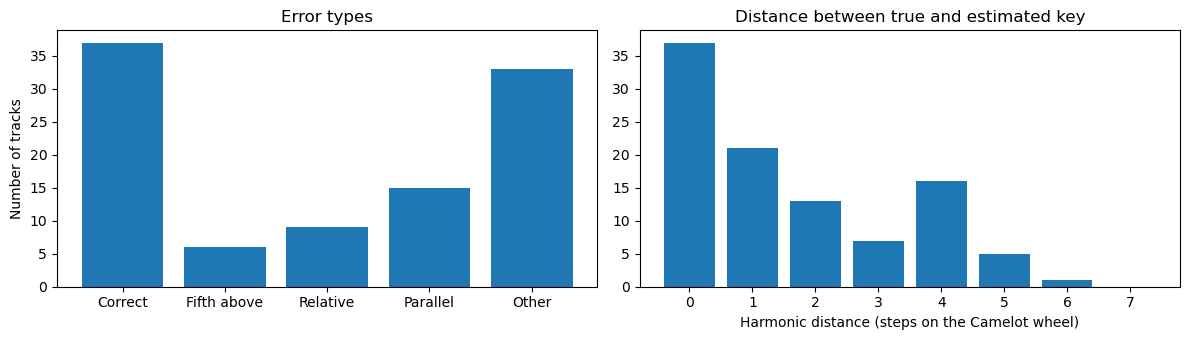

  Correct        37  (37%)
  Fifth above     6  (6%)
  Relative        9  (9%)
  Parallel       15  (15%)
  Other          33  (33%)

Estimates within one step on the Camelot wheel: 58%


In [41]:
CATEGORY = {1.0: "Correct", 0.5: "Fifth above", 0.3: "Relative", 0.2: "Parallel"}
order = ["Correct", "Fifth above", "Relative", "Parallel", "Other"]
categories = Counter(CATEGORY.get(key_score(true, est), "Other") for true, est in results)
distances = np.array([harmonic_distance(true, est) for true, est in results])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].bar(order, [categories[c] for c in order])
axes[0].set_title("Error types")
axes[0].set_ylabel("Number of tracks")
axes[1].bar(range(8), np.bincount(distances, minlength=8))
axes[1].set_title("Distance between true and estimated key")
axes[1].set_xlabel("Harmonic distance (steps on the Camelot wheel)")
plt.tight_layout()
plt.show()

for c in order:
    print(f"  {c:<12}{categories[c]:>5}  ({categories[c] / len(results):.0%})")
print(f"\nEstimates within one step on the Camelot wheel: {np.mean(distances <= 1):.0%}")

Finally, since most tracks are minor, we check whether the detector gets the **mode** right:

In [42]:
modes = ["major", "minor"]
confusion = np.zeros((2, 2), dtype=int)
for true, est in results:
    confusion[modes.index(true.split()[1]), modes.index(est.split()[1])] += 1

print(f"{'':>14}{'est. major':>12}{'est. minor':>12}")
for i, mode in enumerate(modes):
    print(f"{'true ' + mode:>14}{confusion[i, 0]:>12}{confusion[i, 1]:>12}")

                est. major  est. minor
    true major           7           5
    true minor          34          54


### 5.11 Discussion

**Overall performance.** On 100 real dance tracks, the Krumhansl–Schmuckler method finds the exact key for 37 % of the tracks, with a MIREX weighted score of 45.7 %. This is more than twice the optimistic baseline that always predicts the most common key (17 % / 25.4 %) and almost nine times random guessing (4.2 %), so the method clearly extracts tonal information from real recordings, despite drums, bass and vocals. It is, however, far from the perfect results on synthetic cadences in Section 5.4, which shows how much harder real music is.

**The tonic is easier than the mode.** The largest error category is the parallel key (15 tracks): the right tonic with the wrong mode, such as C minor detected as C major. Counting these, the tonic is found for 52 % of the tracks. The confusion matrix shows where the mode errors come from: 34 of the 88 minor tracks were estimated as major, and overall the mode is correct for only 61 tracks, *less* than the 88 % a method that always answers "minor" would achieve. The Krumhansl–Kessler profiles were measured with classical-style tonal music, where major keys and chord progressions dominate. Electronic dance music is mostly in minor, often built on repetitive riffs over few chords, and dominated in energy by drums and bass. Without a clear chord progression, the averaged chroma of a minor track can fit the major profile on the same tonic, or its relative major with identical notes, as well as the correct minor one. Faraldo et al. (2016) observed the same weakness on this dataset and proposed profiles derived from dance music itself.

**What the errors mean for mixing.** The distance distribution has a second peak at distance 4, made almost entirely of the parallel errors: C minor (5A) and C major (8B) share the tonic but only four of seven notes, so the wheel places them far apart. This is the right judgement for a DJ, since clashing notes, not a shared tonic, are what make a transition sound dissonant. In total 58 % of the estimates are within one step of the true key and would still produce a harmonious mix, compared with 37 % exact matches.

**Limitations and improvements.** The evaluation uses 100 of the 604 tracks, so the percentages carry an uncertainty of several points; the full dataset would give more reliable numbers. Clear improvements would be key profiles trained on dance music, reducing the influence of drums before computing the chromagram, and analysing only the harmonic parts of a track. For the auto-DJ, the estimates are useful but should be treated as uncertain, especially the mode.

## 6. Tempo detection

*To be written.*

## 7. Evaluation

*To be written.*

## 8. The transition: crossfades and time-stretching

*To be written.*

## 9. Ordering a set: a graph problem

*To be written.*

## 10. Conclusion, limitations and next steps

*To be written.*

## 11. References

1. M. Müller, *Fundamentals of Music Processing*, 2nd ed., Springer, 2021. Companion notebooks: FMP Notebooks, International Audio Laboratories Erlangen.
2. D. Benson, *Music: A Mathematical Offering*, Cambridge University Press, 2006.
3. W. A. Sethares, *Tuning, Timbre, Spectrum, Scale*, 2nd ed., Springer, 2005.
4. J. O. Smith III, *Mathematics of the Discrete Fourier Transform (DFT)*, CCRMA, Stanford.
5. C. L. Krumhansl, *Cognitive Foundations of Musical Pitch*, Oxford University Press, 1990.
6. E. D. Scheirer, "Tempo and beat analysis of acoustic musical signals," *Journal of the Acoustical Society of America*, 103(1), 1998.
7. D. P. W. Ellis, "Beat tracking by dynamic programming," *Journal of New Music Research*, 36(1), 2007.
8. J. Laroche and M. Dolson, "Improved phase vocoder time-scale modification of audio," *IEEE Transactions on Speech and Audio Processing*, 7(3), 1999.
9. R. Plomp and W. J. M. Levelt, "Tonal consonance and critical bandwidth," *Journal of the Acoustical Society of America*, 38(4), 1965.
10. J. W. Cooley and J. W. Tukey, "An algorithm for the machine calculation of complex Fourier series," *Mathematics of Computation*, 19(90), 1965.
11. W. A. Sethares, "Local consonance and the relationship between timbre and scale," *Journal of the Acoustical Society of America*, 94(3), 1993.
12. C. L. Krumhansl and E. J. Kessler, "Tracing the dynamic changes in perceived tonal organization in a spatial representation of musical keys," *Psychological Review*, 89(4), 1982.
13. P. Knees, Á. Faraldo, P. Herrera, R. Vogl, S. Böck, F. Hörschläger and M. Le Goff, "Two data sets for tempo estimation and key detection in electronic dance music annotated from user corrections," *Proceedings of the 16th International Society for Music Information Retrieval Conference (ISMIR)*, 2015.
14. Á. Faraldo, E. Gómez, S. Jordà and P. Herrera, "Key estimation in electronic dance music," *Proceedings of the European Conference on Information Retrieval (ECIR)*, 2016.

**Software**

15. C. R. Harris et al., "Array programming with NumPy," *Nature*, 585, 2020.
16. P. Virtanen et al., "SciPy 1.0: Fundamental algorithms for scientific computing in Python," *Nature Methods*, 17, 2020.
17. J. D. Hunter, "Matplotlib: A 2D graphics environment," *Computing in Science & Engineering*, 9(3), 2007.
18. B. McFee et al., "librosa: Audio and music signal analysis in Python," *Proceedings of the 14th Python in Science Conference*, 2015.

**Data.** The GiantSteps Key dataset [13] is used for evaluation only. Its audio previews are downloaded locally by `scripts/download_data.py` and are not redistributed in this repository.